# 12. Lagrangian mechanics: from energies to a chaotic double pendulum

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/12_lagrangian_mechanics.ipynb)

Deriving equations of motion with free-body diagrams becomes painful as soon as a mechanism has
two moving parts. The Lagrangian method needs only the kinetic energy $T$ and potential energy
$V$: with $\mathcal{L} = T - V$, each coordinate $q$ obeys

$$\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot q} - \frac{\partial\mathcal{L}}{\partial q} = 0 .$$

The differentiation is long and error-prone by hand, and entirely mechanical for SymPy.

This notebook brings together most of the course: symbolic derivation (notebooks 3 and 4),
`lambdify` and numerical integration (8), linearization (9), and verification at every step.

**Worked examples:** a simple pendulum, then the double pendulum: derivation, simulation,
energy check, normal modes, sensitivity to initial conditions, and an animation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from sympy.calculus.euler import euler_equations

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 12.1 Warm-up: the simple pendulum

A mass $m$ on a rod of length $l$. Write the position, differentiate for the velocity, and
form the energies.

In [2]:
t = sp.symbols("t")
m, l, g = sp.symbols("m l g", positive=True)
theta = sp.Function("theta")(t)

x, y = l * sp.sin(theta), -l * sp.cos(theta)
T = sp.simplify(m * (x.diff(t) ** 2 + y.diff(t) ** 2) / 2)
V = m * g * y

pendulum = euler_equations(T - V, theta, t)[0]
pendulum

                         2           
                    2   d            
-g⋅l⋅m⋅sin(θ(t)) - l ⋅m⋅───(θ(t)) = 0
                          2          
                        dt           

In [3]:
# verify: this is the familiar  θ'' = -(g/l) sin θ
assert sp.solve(pendulum, theta.diff(t, 2))[0] == -g * sp.sin(theta) / l

## 12.2 The double pendulum

**Problem.** A second pendulum (mass $m_2$, length $l_2$) hangs from the bob of the first
($m_1$, $l_1$). Find the equations of motion for the two angles, measured from the vertical.

**By hand** this takes a couple of pages. Here the only physics you supply is the position of
each mass.

In [4]:
m1, m2, l1, l2 = sp.symbols("m_1 m_2 l_1 l_2", positive=True)
th1 = sp.Function("theta_1")(t)
th2 = sp.Function("theta_2")(t)

x1, y1 = l1 * sp.sin(th1), -l1 * sp.cos(th1)
x2, y2 = x1 + l2 * sp.sin(th2), y1 - l2 * sp.cos(th2)

T = sp.simplify(m1 * (x1.diff(t) ** 2 + y1.diff(t) ** 2) / 2 + m2 * (x2.diff(t) ** 2 + y2.diff(t) ** 2) / 2)
V = m1 * g * y1 + m2 * g * y2
T

                  2      ⎛               2                                     ↪
  2    ⎛d        ⎞       ⎜  2 ⎛d        ⎞                               d      ↪
l₁ ⋅m₁⋅⎜──(θ₁(t))⎟    m₂⋅⎜l₁ ⋅⎜──(θ₁(t))⎟  + 2⋅l₁⋅l₂⋅cos(θ₁(t) - θ₂(t))⋅──(θ₁( ↪
       ⎝dt       ⎠       ⎝    ⎝dt       ⎠                               dt     ↪
─────────────────── + ──────────────────────────────────────────────────────── ↪
         2                                                        2            ↪

↪                                2⎞
↪     d             2 ⎛d        ⎞ ⎟
↪ t))⋅──(θ₂(t)) + l₂ ⋅⎜──(θ₂(t))⎟ ⎟
↪     dt              ⎝dt       ⎠ ⎠
↪ ─────────────────────────────────
↪                                  

In [5]:
equations = euler_equations(T - V, [th1, th2], t)
[sp.simplify(eq.lhs) for eq in equations]

⎡    ⎛                                           2                  2          ↪
⎢    ⎜                                          d                  d           ↪
⎢-l₁⋅⎜g⋅m₁⋅sin(θ₁(t)) + g⋅m₂⋅sin(θ₁(t)) + l₁⋅m₁⋅───(θ₁(t)) + l₁⋅m₂⋅───(θ₁(t))  ↪
⎢    ⎜                                            2                  2         ↪
⎣    ⎝                                          dt                 dt          ↪

↪                                       2                             2        ↪
↪                            ⎛d        ⎞                             d         ↪
↪ + l₂⋅m₂⋅sin(θ₁(t) - θ₂(t))⋅⎜──(θ₂(t))⎟  + l₂⋅m₂⋅cos(θ₁(t) - θ₂(t))⋅───(θ₂(t) ↪
↪                            ⎝dt       ⎠                               2       ↪
↪                                                                    dt        ↪

↪  ⎞        ⎛                                                 2                ↪
↪  ⎟        ⎜                                      ⎛d        ⎞                 ↪
↪ )⎟, l₂⋅m₂⋅⎜-g⋅sin(θ₂(t))

The two equations are coupled: each contains both angular accelerations. They are linear in the
accelerations, so `solve` separates them.

In [6]:
accelerations = sp.solve(equations, [th1.diff(t, 2), th2.diff(t, 2)], dict=True)[0]
alpha1 = sp.simplify(accelerations[th1.diff(t, 2)])
alpha2 = sp.simplify(accelerations[th2.diff(t, 2)])
alpha1

                                                                               ↪
                                                                               ↪
                                                                 l₁⋅m₂⋅sin(2⋅θ ↪
                   g⋅m₂⋅sin(θ₁(t) - 2⋅θ₂(t))   g⋅m₂⋅sin(θ₁(t))                 ↪
-g⋅m₁⋅sin(θ₁(t)) - ───────────────────────── - ─────────────── - ───────────── ↪
                               2                      2                        ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                         ⎛           2         ↪
                                                      l₁⋅⎝m₁ - m₂⋅cos (θ₁(t) - ↪

↪                            2                                        
↪                 ⎛d        ⎞                                         
↪ ₁(t) - 2⋅θ₂(t))⋅⎜──(θ₁(t))⎟                                        2
↪                 ⎝dt       ⎠                            

**Verify** with a limiting case: if the second mass is removed ($m_2 \to 0$), the first
pendulum must behave like the simple pendulum of 12.1.

In [7]:
assert sp.simplify(alpha1.subs(m2, 0) + g * sp.sin(th1) / l1) == 0

## 12.3 From equations to a simulation

Replace the functions of time by plain symbols, then `lambdify` the first-order system
$(\theta_1, \theta_2, \omega_1, \omega_2)$ for `solve_ivp`.

In [8]:
q1, q2, w1, w2 = sp.symbols("q_1 q_2 omega_1 omega_2")
to_symbols = {th1.diff(t): w1, th2.diff(t): w2, th1: q1, th2: q2}       # derivatives first
params = {m1: 1.0, m2: 1.0, l1: 1.0, l2: 1.0, g: 9.81}

rhs = sp.lambdify((q1, q2, w1, w2),
                  [w1, w2, alpha1.subs(to_symbols).subs(params), alpha2.subs(to_symbols).subs(params)], "numpy")
energy = sp.lambdify((q1, q2, w1, w2), (T + V).subs(to_symbols).subs(params), "numpy")

def simulate(theta1_deg, theta2_deg, t_end=20.0, points=2001):
    times = np.linspace(0, t_end, points)
    start = [np.radians(theta1_deg), np.radians(theta2_deg), 0.0, 0.0]
    sol = solve_ivp(lambda _, state: rhs(*state), [0, t_end], start, t_eval=times, rtol=1e-10, atol=1e-10)
    return times, sol.y

times, motion = simulate(120, -20)

**Verify.** There is no friction, so the total energy $T + V$ must stay constant. This tests
the derivation and the numerical integration together.

In [9]:
E = energy(*motion)
drift = np.abs(E - E[0]).max()
print(f"initial energy {E[0]:.4f} J     largest drift over 20 s: {drift:.1e} J")
assert drift < 1e-5

initial energy 0.5916 J     largest drift over 20 s: 7.2e-08 J


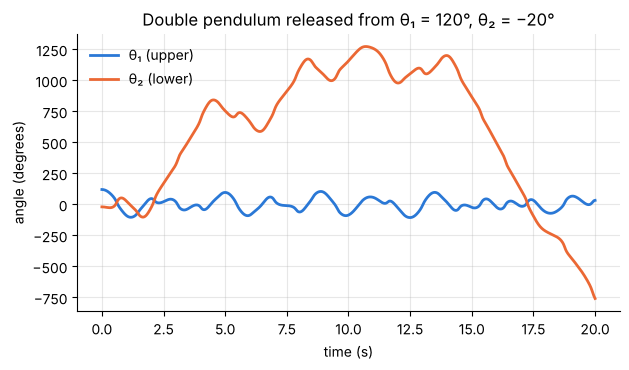

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(times, np.degrees(motion[0]), label="θ₁ (upper)")
ax.plot(times, np.degrees(motion[1]), label="θ₂ (lower)")
ax.set(xlabel="time (s)", ylabel="angle (degrees)", title="Double pendulum released from θ₁ = 120°, θ₂ = −20°")
ax.legend(frameon=False, loc="upper left");

Nothing like the tidy sine wave of a single pendulum.

## 12.4 Small oscillations: normal modes

For small angles the motion *is* regular: a combination of two normal modes. Linearizing about
the hanging position (notebook 9) gives their frequencies.

**By hand**, for equal masses and lengths, textbooks give $\omega^2 = (2 \pm \sqrt2)\,g/l$.

In [11]:
acc = sp.Matrix([alpha1, alpha2]).subs(to_symbols)
at_rest = {q1: 0, q2: 0, w1: 0, w2: 0}
stiffness = -acc.jacobian([q1, q2]).subs(at_rest).subs({m2: m1, l2: l1})    # θ'' = -K θ

omega_squared = [sp.simplify(val) for val in stiffness.eigenvals()]
omega_squared

⎡g⋅(2 - √2)  g⋅(√2 + 2)⎤
⎢──────────, ──────────⎥
⎣    l₁          l₁    ⎦

In [12]:
assert set(omega_squared) == {sp.simplify((2 - sp.sqrt(2)) * g / l1), sp.simplify((2 + sp.sqrt(2)) * g / l1)}

# and the simulation agrees: a small swing started in the slow mode shape keeps a single frequency
slow_mode = stiffness.eigenvects()[0]
ratio = float((slow_mode[2][0][1] / slow_mode[2][0][0]))          # θ₂/θ₁ in that mode (= √2)
ts, small = simulate(1.0, ratio, t_end=30, points=6001)
crossings = ts[1:][(small[0][:-1] < 0) & (small[0][1:] >= 0)]
period_sim = np.diff(crossings).mean()
period_theory = 2 * np.pi / np.sqrt(float(slow_mode[0].subs({g: 9.81, l1: 1.0})))
print(f"slow mode: θ₂/θ₁ = {ratio:.3f}    period from simulation {period_sim:.4f} s    theory {period_theory:.4f} s")
assert abs(period_sim / period_theory - 1) < 1e-3

slow mode: θ₂/θ₁ = 1.414    period from simulation 2.6210 s    theory 2.6211 s


## 12.5 Sensitivity to initial conditions

Release two double pendulums whose starting angles differ by one millionth of a radian
(about 0.00006°).

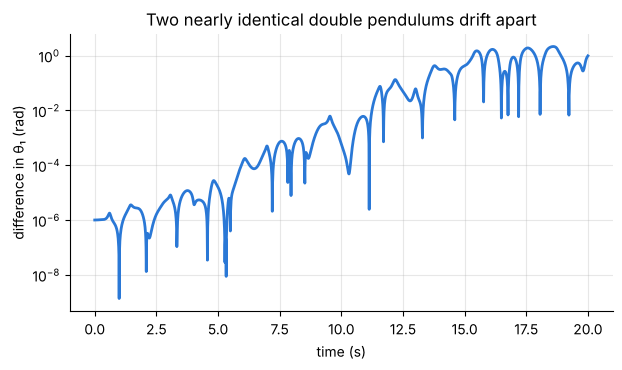

In [13]:
_, twin = simulate(120 + np.degrees(1e-6), -20)
separation = np.abs(motion[0] - twin[0])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(times, separation)
ax.set(xlabel="time (s)", ylabel="difference in θ₁ (rad)", title="Two nearly identical double pendulums drift apart");

In [14]:
assert separation[-1] > 1e4 * separation[0]
print(f"after 20 s the difference has grown by a factor of about {separation.max() / 1e-6:,.0f}")

after 20 s the difference has grown by a factor of about 2,140,612


The difference grows roughly exponentially until the two motions are unrelated. This is
deterministic chaos: the equations are exact, yet long-term prediction is impossible because no
initial condition is ever known to infinite precision. It is the same reason weather forecasts
lose skill after a week or two.

## 12.6 Trajectory and animation

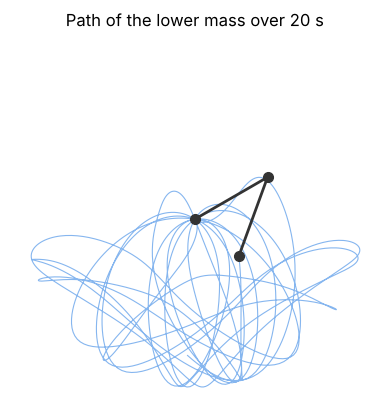

In [15]:
def positions(state):
    px1, py1 = np.sin(state[0]), -np.cos(state[0])
    return px1, py1, px1 + np.sin(state[1]), py1 - np.cos(state[1])

px1, py1, px2, py2 = positions(motion)

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(px2, py2, lw=0.8, color="#86b6ef")
ax.plot([0, px1[0], px2[0]], [0, py1[0], py2[0]], "o-", color="0.2", lw=2, ms=7)
ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal", title="Path of the lower mass over 20 s")
ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)

In [16]:
from matplotlib.animation import FuncAnimation, PillowWriter

frames = range(0, 1000, 5)                 # the first 10 s, every 0.05 s
fig, ax = plt.subplots(figsize=(3.6, 3.6), dpi=80)
ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal")
ax.axis("off")
trail, = ax.plot([], [], lw=1, color="#86b6ef")
rods, = ax.plot([], [], "o-", color="0.2", lw=2, ms=7)

def draw(i):
    trail.set_data(px2[max(0, i - 150):i + 1], py2[max(0, i - 150):i + 1])
    rods.set_data([0, px1[i], px2[i]], [0, py1[i], py2[i]])
    return trail, rods

FuncAnimation(fig, draw, frames=frames, blit=True).save("double_pendulum.gif", writer=PillowWriter(fps=20))
plt.close(fig)
print("saved double_pendulum.gif")

saved double_pendulum.gif


![Animated double pendulum](double_pendulum.gif)

(If the animation does not show here, open `double_pendulum.gif`, which the cell above saved
next to this notebook.)

## Going further

For larger mechanisms SymPy has a dedicated package, `sympy.physics.mechanics`, with reference
frames, rigid bodies, applied forces and both Lagrange's and Kane's methods. Notebook 15
introduces it and uses it to balance an inverted pendulum. The approach above,
positions → energies → `euler_equations`, is enough for most course problems and keeps every
step visible.

## Exercises

1. A bead slides without friction on a parabola $y = a x^2$ under gravity. Derive its equation
   of motion with $x$ as the coordinate, and find the frequency of small oscillations.
2. A pendulum hangs from a cart of mass $M$ that rolls freely on a horizontal track. Derive
   both equations of motion and show that the total horizontal momentum is conserved.
3. Add a spring to the simple pendulum (the rod can stretch, coordinate $r$). Derive the two
   equations and simulate the motion for $m = 1$ kg, stiffness $k = 40$ N/m and unstretched
   length $l_0 = 1$ m, released from rest at 60° with the spring at its hanging length
   $l_0 + mg/k$.
4. Start the double pendulum from 10° and 10°. Is the motion still sensitive to the initial
   conditions? Repeat 12.5 and compare the growth.
5. With equal lengths, make the lower mass ten times heavier. How do the two normal-mode
   frequencies change?